# EDA + preprocessing

In [1]:
import pandas as pd
import numpy as np
from scipy.spatial.distance import cdist

DATA_PATH = "/Users/vale/Desktop/data_mining/assignment3/"

train = pd.read_csv(DATA_PATH + "train.csv")
features = pd.read_csv(DATA_PATH + "features.csv")
stores = pd.read_csv(DATA_PATH + "stores.csv")

In [2]:
train.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [3]:
features.head()

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


In [4]:
stores.head()

,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


Check basic structure

In [5]:

for name, df in {"train": train, "features": features, "stores": stores}.items():
    print(f"\n{name.upper()}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())
    display(df.dtypes)


TRAIN
Shape: (421570, 5)
Columns: ['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday']


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


Store             int64
Dept              int64
Date             object
Weekly_Sales    float64
IsHoliday          bool
dtype: object


FEATURES
Shape: (8190, 12)
Columns: ['Store', 'Date', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'IsHoliday']


,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


Store             int64
Date             object
Temperature     float64
Fuel_Price      float64
MarkDown1       float64
MarkDown2       float64
MarkDown3       float64
MarkDown4       float64
MarkDown5       float64
CPI             float64
Unemployment    float64
IsHoliday          bool
dtype: object


STORES
Shape: (45, 3)
Columns: ['Store', 'Type', 'Size']


,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


Store     int64
Type     object
Size      int64
dtype: object

Check data coverage

In [6]:

print("Train date range:", train["Date"].min(), "to", train["Date"].max())
print("Features date range:", features["Date"].min(), "to", features["Date"].max())

print("\nNumber of stores:", train["Store"].nunique())
print("Number of departments:", train["Dept"].nunique())
print("Number of Store–Dept combinations:",
      train[["Store", "Dept"]].drop_duplicates().shape[0])

print("\nRows per Store–Dept combination:")
display(
    train.groupby(["Store", "Dept"]).size().describe()
)

Train date range: 2010-02-05 to 2012-10-26
Features date range: 2010-02-05 to 2013-07-26

Number of stores: 45
Number of departments: 81
Number of Store–Dept combinations: 3331

Rows per Store–Dept combination:


count    3331.000000
mean      126.559592
std        40.212763
min         1.000000
25%       143.000000
50%       143.000000
75%       143.000000
max       143.000000
dtype: float64

BusPaS needs descriptive variables and target variables, not a sales-forecasting feature matrix. Markdown variables are omitted because the provided BusPaS setup does not use them and they contain extensive missingness.

In [7]:
features = features[["Store", "Date", "IsHoliday", "Temperature", "Fuel_Price", "CPI", "Unemployment"]].copy()

Check missing values -> no missing values

In [8]:

print("Missing values in train:")
display(train.isna().sum().sort_values(ascending=False))

print("\nMissing values in features:")
display(features.isna().sum().sort_values(ascending=False))

print("\nMissing values in stores:")
display(stores.isna().sum().sort_values(ascending=False))

Missing values in train:


Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64


Missing values in features:


CPI             585
Unemployment    585
Store             0
Date              0
IsHoliday         0
Temperature       0
Fuel_Price        0
dtype: int64


Missing values in stores:


Store    0
Type     0
Size     0
dtype: int64

Checking duplicates

In [9]:
train["Date"] = pd.to_datetime(train["Date"], errors="coerce")
features["Date"] = pd.to_datetime(features["Date"], errors="coerce")

print("Missing dates in train:", train["Date"].isna().sum())
print("Missing dates in features:", features["Date"].isna().sum())

print("Duplicate Store–Dept–Date rows in train:",
      train.duplicated(["Store", "Dept", "Date"]).sum())

print("Duplicate Store–Date rows in features:",
      features.duplicated(["Store", "Date"]).sum())

print("Duplicate Store rows in stores:",
      stores.duplicated(["Store"]).sum())

Missing dates in train: 0
Missing dates in features: 0
Duplicate Store–Dept–Date rows in train: 0
Duplicate Store–Date rows in features: 0
Duplicate Store rows in stores: 0


We remove null values and negative values because negative values usually reflect refund and can distort a store's average sales

In [10]:
train_clean = train.dropna(subset=["Store", "Dept", "Date", "Weekly_Sales"]).copy()

negative_sales = (train_clean["Weekly_Sales"] < 0).sum()
print("Negative Weekly_Sales rows:", negative_sales)

# Treat negative values as returns/refunds, not normal weekly demand.
train_clean = train_clean[train_clean["Weekly_Sales"] >= 0].copy()

Negative Weekly_Sales rows: 1285


Check sales distribution

The graphs show that weekly_sales is strongly right skewed, and in the boxplot there are many outlier values, but we don't remove these values because in retail data is high values might be meaningful since large stores can genuinely sell much more than others

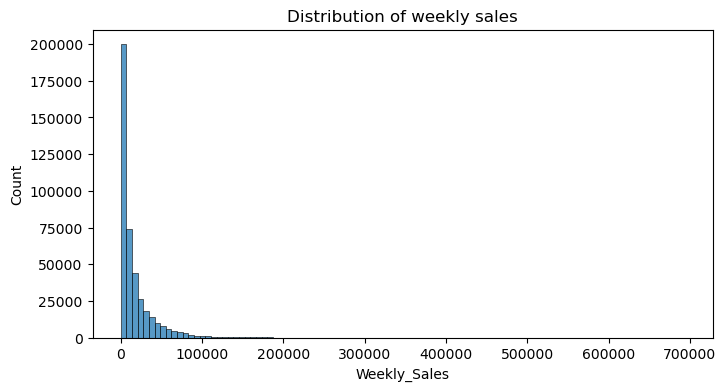

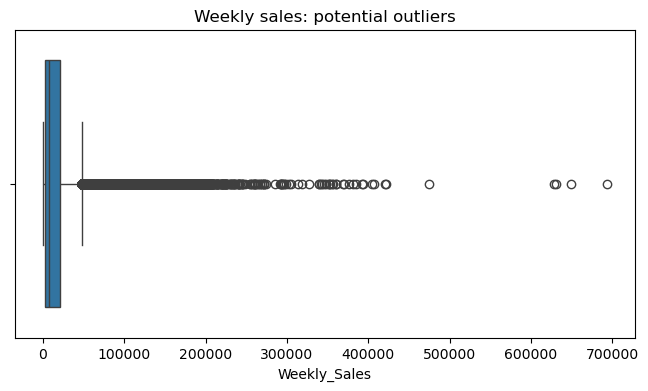

In [11]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.histplot(train_clean["Weekly_Sales"], bins=100)
plt.title("Distribution of weekly sales")
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(x=train_clean["Weekly_Sales"])
plt.title("Weekly sales: potential outliers")
plt.show()

The highest weekly sales values are mainly generated by Department 72 across multiple stores. Since these Store–Department combinations also have high average and total sales over all 143 weeks, the extreme values appear to be genuine retail differences rather than isolated data errors. Therefore, they are retained.

In [12]:
# Check which Store–Department combinations produce the highest sales
display(
    train_clean.groupby(["Store", "Dept"])["Weekly_Sales"]
    .agg(["mean", "max", "sum", "count"])
    .sort_values("max", ascending=False)
    .head(10)
)

,,mean,max,sum,count
Store,Dept,,,,
10,72,142733.752168,693099.36,20410926.56,143
35,72,88331.808881,649770.18,12631448.67,143
14,72,94140.832867,474330.10,13462139.10,143
20,72,91989.863217,422306.25,13154550.44,143
27,72,68527.765944,420586.57,9799470.53,143
10,7,58964.715664,406988.63,8431954.34,143
22,72,66645.669021,393705.20,9530330.67,143
4,72,101244.450839,385051.04,14477956.47,143
23,72,76844.022727,369830.98,10988695.25,143


We can also inspect the difference between holiday and non holiday sales. 

The results that we get say that weekly sales are higher during holiday weeks: both the mean and median sales increase compared with non-holiday weeks. Holiday sales also show greater variability, suggesting that holidays affect stores and departments differently. 

In [13]:

holiday_sales = (
    train_clean.groupby("IsHoliday")["Weekly_Sales"]
    .agg(["count", "mean", "median", "std"])
)

display(holiday_sales)

,count,mean,median,std
IsHoliday,,,,
False,390722,15949.958317,7636.08,22347.258698
True,29563,17092.566220,7997.86,27249.206776


We check if every store-department combination has data for each week

The dataset contains 143 weekly dates. Of the 3,323 Store–Department combinations, 695 do not have sales observations for every week. Because BUSPaS compares sales trajectories, only combinations with complete 143-week time series are retained to ensure fair and consistent comparison.

In [14]:
expected_weeks = train_clean["Date"].nunique()

series_lengths = train_clean.groupby(["Store", "Dept"])["Date"].nunique()

print("Expected number of weeks:", expected_weeks)
print("Store–Dept series lengths:")
display(series_lengths.describe())

print("Incomplete Store–Dept series:",
      (series_lengths < expected_weeks).sum())

Expected number of weeks: 143
Store–Dept series lengths:


count    3323.000000
mean      126.477580
std        40.302689
min         1.000000
25%       143.000000
50%       143.000000
75%       143.000000
max       143.000000
Name: Date, dtype: float64

Incomplete Store–Dept series: 695


In [15]:
# Keep only Store–Department combinations with all 143 weekly dates
train_complete = (
    train_clean
    .groupby(["Store", "Dept"])
    .filter(lambda group: group["Date"].nunique() == expected_weeks)
    .copy()
)

print("Rows before:", len(train_clean))
print("Rows after:", len(train_complete))

print("Complete Store–Department combinations:",
      train_complete[["Store", "Dept"]].drop_duplicates().shape[0])

Rows before: 420285
Rows after: 375804
Complete Store–Department combinations: 2628


We merge the three datasets into one

In [16]:
walmart_data = (
    train_complete
    .merge(features, on=["Store", "Date", "IsHoliday"], how="left")
    .merge(stores, on="Store", how="left")
)

print("Merged shape:", walmart_data.shape)
print("Rows lost compared with train_complete:", len(train_complete) - len(walmart_data))

print("\nMissing values after merging:")
display(walmart_data.isna().sum().sort_values(ascending=False))

Merged shape: (375804, 11)
Rows lost compared with train_complete: 0

Missing values after merging:


Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
Type            0
Size            0
dtype: int64

We try plotting the weekly sales pattern for store 1 department 1

Weekly sales are generally stable at around 15,000–25,000, but there are repeated sharp peaks reaching approximately 50,000–58,000. These recurring peaks suggest seasonal or holiday-related demand. This illustrates the type of sales behaviour that BUSPaS can compare across Store–Department combinations to identify exceptional patterns.

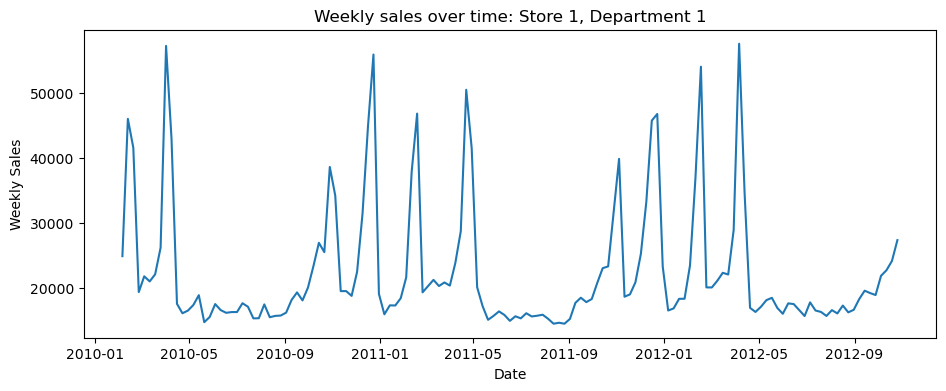

In [17]:

example = walmart_data[(walmart_data["Store"] == 1) & (walmart_data["Dept"] == 1)].sort_values("Date")

plt.figure(figsize=(11, 4))
plt.plot(example["Date"], example["Weekly_Sales"])
plt.title("Weekly sales over time: Store 1, Department 1")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.show()

We also inspect the association between weekly sales for each store, tempeature, fuel price, CPI and unemployment.

The visualisations show weak overall linear associations between total weekly sales and temperature, fuel price, CPI, and unemployment. Fuel price has virtually no relationship with sales, while temperature, CPI, and unemployment show only slight negative trends. Therefore, these variables do not appear to strongly explain overall sales levels on their own. However, they may still affect particular Store–Department subgroups differently, which BUSPaS can investigate through subgroup-specific response measures.

In [18]:
# One row per Store–Date: total sales and that week's external conditions
store_week = (
    walmart_data
    .groupby(["Store", "Date"], as_index=False)
    .agg(
        Total_Weekly_Sales=("Weekly_Sales", "sum"),
        Temperature=("Temperature", "first"),
        Fuel_Price=("Fuel_Price", "first"),
        CPI=("CPI", "first"),
        Unemployment=("Unemployment", "first"),
        IsHoliday=("IsHoliday", "first")
    )
)

display(store_week.head())

,Store,Date,Total_Weekly_Sales,Temperature,Fuel_Price,CPI,Unemployment,IsHoliday
0,1,2010-02-05,1631850.77,42.31,2.572,211.096358,8.106,False
1,1,2010-02-12,1613123.36,38.51,2.548,211.242170,8.106,True
2,1,2010-02-19,1588101.37,39.93,2.514,211.289143,8.106,False
3,1,2010-02-26,1403322.44,46.63,2.561,211.319643,8.106,False
4,1,2010-03-05,1548866.58,46.50,2.625,211.350143,8.106,False


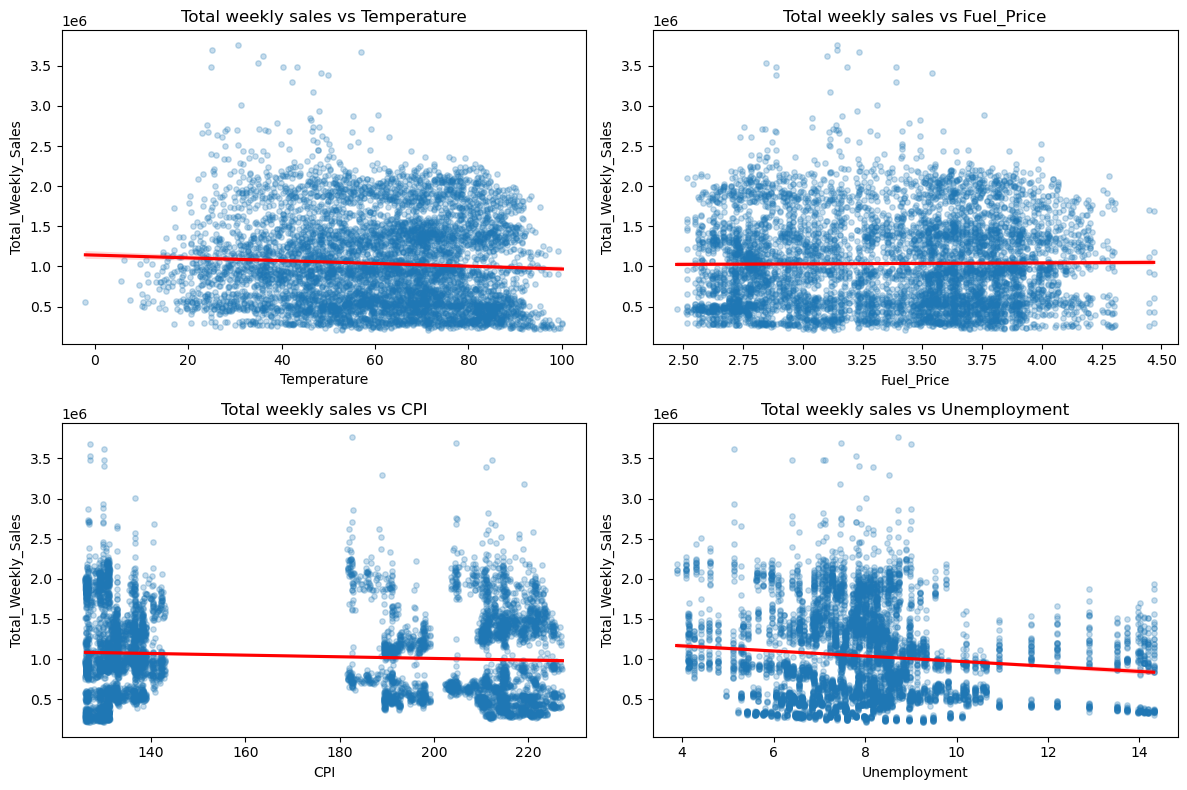

In [19]:
variables = ["Temperature", "Fuel_Price", "CPI", "Unemployment"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, variable in zip(axes.flat, variables):
    sns.regplot(
        data=store_week,
        x=variable,
        y="Total_Weekly_Sales",
        scatter_kws={"alpha": 0.25, "s": 15},
        line_kws={"color": "red"},
        ax=ax
    )
    ax.set_title(f"Total weekly sales vs {variable}")

plt.tight_layout()
plt.show()

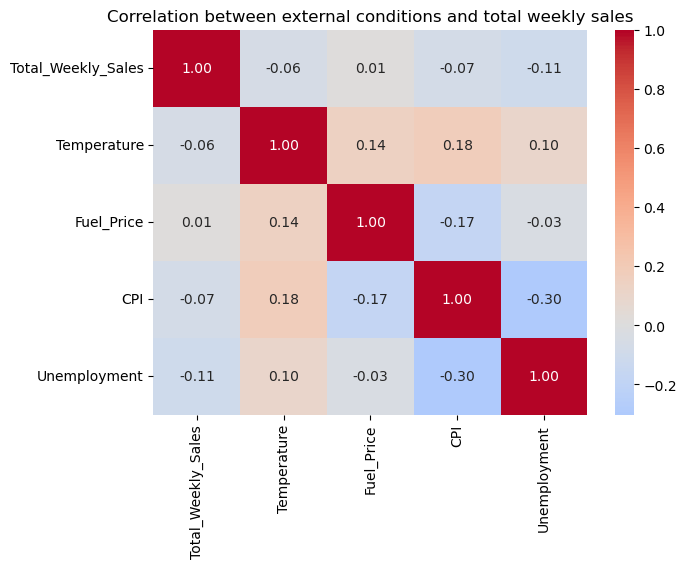

In [20]:
plt.figure(figsize=(7, 5))

correlation = store_week[
    ["Total_Weekly_Sales", "Temperature", "Fuel_Price", "CPI", "Unemployment"]
].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation between external conditions and total weekly sales")
plt.show()

Next we inspect the relation between store-department combination weekly sales and the other variables. 

The boxplot below uses all 143 weekly observations for each Store–Department combination. For every combination, it calculates the correlation between its Weekly_Sales values and the corresponding weekly values of Temperature, Fuel_Price, CPI, and Unemployment. The plot summarizes these correlation values across all Store–Department combinations. Although the median correlations are close to zero, the wide spread shows that sales sensitivity differs substantially across combinations. Some pairs have strong positive or negative relationships, making these variables useful for deriving BUSPaS target measures.

In [21]:
variables = ["Temperature", "Fuel_Price", "CPI", "Unemployment"]

def sales_correlations(group):
    return pd.Series({
        variable: group["Weekly_Sales"].corr(group[variable])
        for variable in variables
    })

pair_correlations = (
    walmart_data
    .groupby(["Store", "Dept"])[["Weekly_Sales"] + variables]
    .apply(sales_correlations)
)

display(pair_correlations.head())

Temperature  Fuel_Price       CPI  Unemployment
Store Dept                                                 
1     1       -0.473860   -0.066396 -0.043533      0.103399
      2       -0.014821    0.034471  0.121627     -0.045789
      3        0.336490    0.027219  0.072986     -0.089588
      4        0.009820    0.031813  0.230685     -0.175366
      5       -0.511538   -0.128661 -0.019696      0.166538

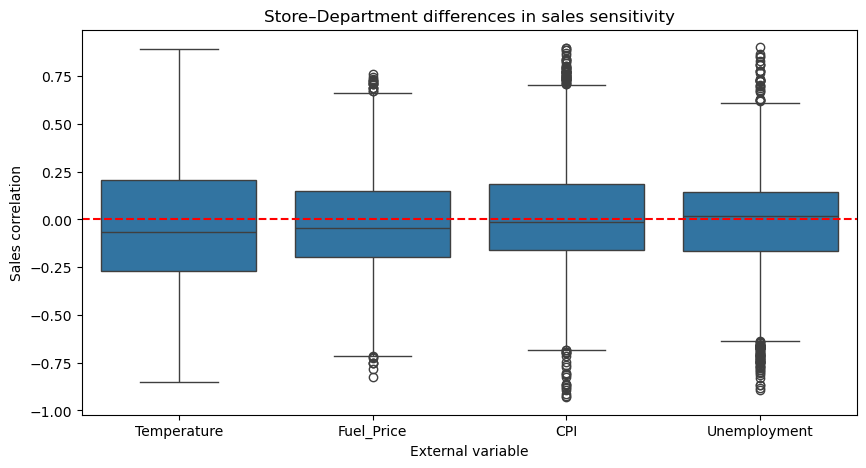

In [22]:
pair_correlations_long = pair_correlations.reset_index().melt(
    id_vars=["Store", "Dept"],
    value_vars=variables,
    var_name="External variable",
    value_name="Sales correlation"
)

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=pair_correlations_long,
    x="External variable",
    y="Sales correlation"
)
plt.axhline(0, color="red", linestyle="--")
plt.title("Store–Department differences in sales sensitivity")
plt.show()

# Quality measure EDA

In [23]:
# One row = one Store–Department combination
# One column = one weekly date
# This is the target input needed for both quality-measure checks.

sales_matrix = (
    walmart_data
    .pivot(index=["Store", "Dept"], columns="Date", values="Weekly_Sales")
    .sort_index(axis=1)
)

print("Trajectory matrix shape:", sales_matrix.shape)
print("Missing values in trajectory matrix:", sales_matrix.isna().sum().sum())
print("Number of weekly dates:", sales_matrix.shape[1])

display(sales_matrix.iloc[:5, :5])

Trajectory matrix shape: (2628, 143)
Missing values in trajectory matrix: 0
Number of weekly dates: 143


Date        2010-02-05  2010-02-12  2010-02-19  2010-02-26  2010-03-05
Store Dept                                                            
1     1       24924.50    46039.49    41595.55    19403.54    21827.90
      2       50605.27    44682.74    47928.89    44292.87    48397.98
      3       13740.12    10887.84    11523.47    11135.17    12275.58
      4       39954.04    35351.21    36826.95    34660.16    38086.19
      5       32229.38    29620.81    26468.27    24101.89    23082.14

The analysis below tell us if buspas measure is suitable, to do this we see if there is enough distance between the different shapes because the measure relies on the distance between pairs.

The data are suitable for the BUSPaS clustering quality measure. The dataset contains 2,628 complete, non-constant Store–Department sales trajectories with a common length of 143 weeks. Raw Euclidean distances are strongly influenced by large differences in absolute sales level; therefore, applying the measure to raw sales would primarily identify high- or low-sales groups. After standardising each trajectory individually, pairwise distances retain substantial variation, demonstrating that the data contain distinguishable sales shapes. Hence, the standardised trajectories are appropriate input for the BUSPaS distance-based quality measure when the aim is to find exceptional long-term sales patterns.

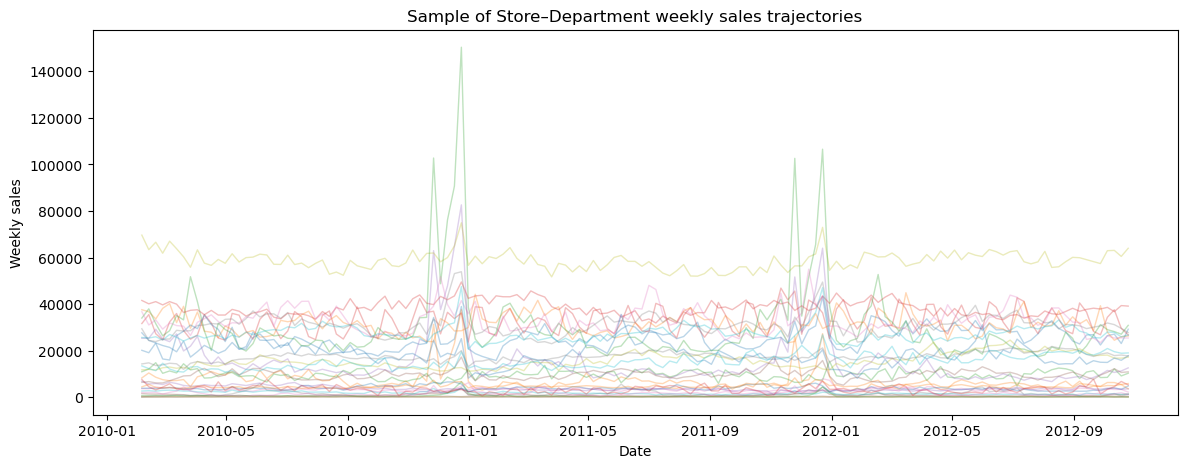

In [24]:
# Plot several Store–Department sales trajectories, rather than only one example

sample_trajectories = sales_matrix.sample(30, random_state=42)

plt.figure(figsize=(14, 5))

for _, trajectory in sample_trajectories.iterrows():
    plt.plot(
        sales_matrix.columns,
        trajectory.values,
        alpha=0.30,
        linewidth=1
    )

plt.title("Sample of Store–Department weekly sales trajectories")
plt.xlabel("Date")
plt.ylabel("Weekly sales")
plt.show()

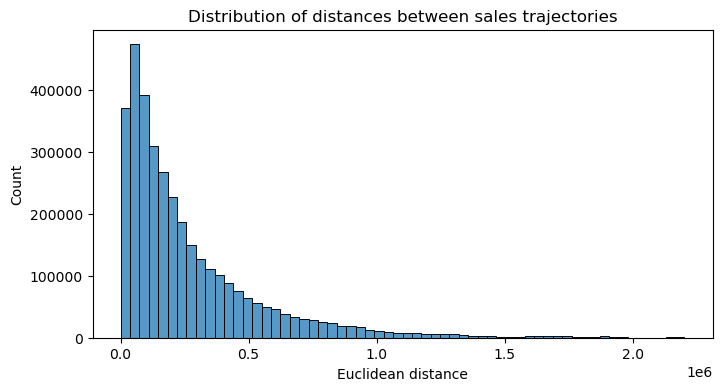

count    3.451878e+06
mean     2.686811e+05
std      2.879904e+05
min      2.005658e+02
25%      7.514622e+04
50%      1.711984e+05
75%      3.585603e+05
max      2.202175e+06
dtype: float64


In [25]:
# Examine how different trajectories are when Euclidean distance is used

from scipy.spatial.distance import pdist

raw_distances = pdist(sales_matrix.values, metric="euclidean")

plt.figure(figsize=(8, 4))
sns.histplot(raw_distances, bins=60)
plt.title("Distribution of distances between sales trajectories")
plt.xlabel("Euclidean distance")
plt.show()

print(pd.Series(raw_distances).describe())

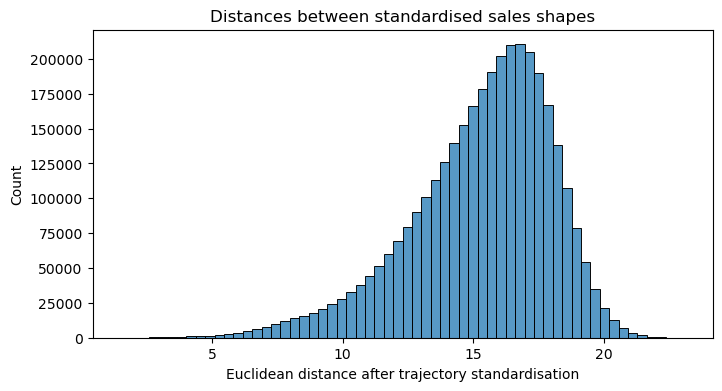

In [26]:
# Compare trajectory shapes after removing each trajectory's own sales level and scale.
# Do this only if your goal is "unusual shape over time".

sales_matrix_shape = sales_matrix.sub(sales_matrix.mean(axis=1), axis=0).div(
    sales_matrix.std(axis=1).replace(0, np.nan),
    axis=0
)

shape_distances = pdist(sales_matrix_shape.values, metric="euclidean")

plt.figure(figsize=(8, 4))
sns.histplot(shape_distances, bins=60)
plt.title("Distances between standardised sales shapes")
plt.xlabel("Euclidean distance after trajectory standardisation")
plt.show()

Next we see if RCS or rankbiserial correlation is suitable by analysing skewness of data. 

As shown earlier, the original weekly sales values are strongly right-skewed, with a small number of Store–Department combinations having exceptionally large sales. After standardising each Store–Department trajectory to remove its own average sales level and scale, the cross-sectional sales distributions at individual weeks remain asymmetric with long positive tails. Thus, standardisation supports shape-based comparison but does not make the target values normally distributed. Therefore, we use rank-biserial correlation rather than a mean and standard-error based score, because it compares subgroup and complement using ranks and is robust to skewed distributions and extreme values.


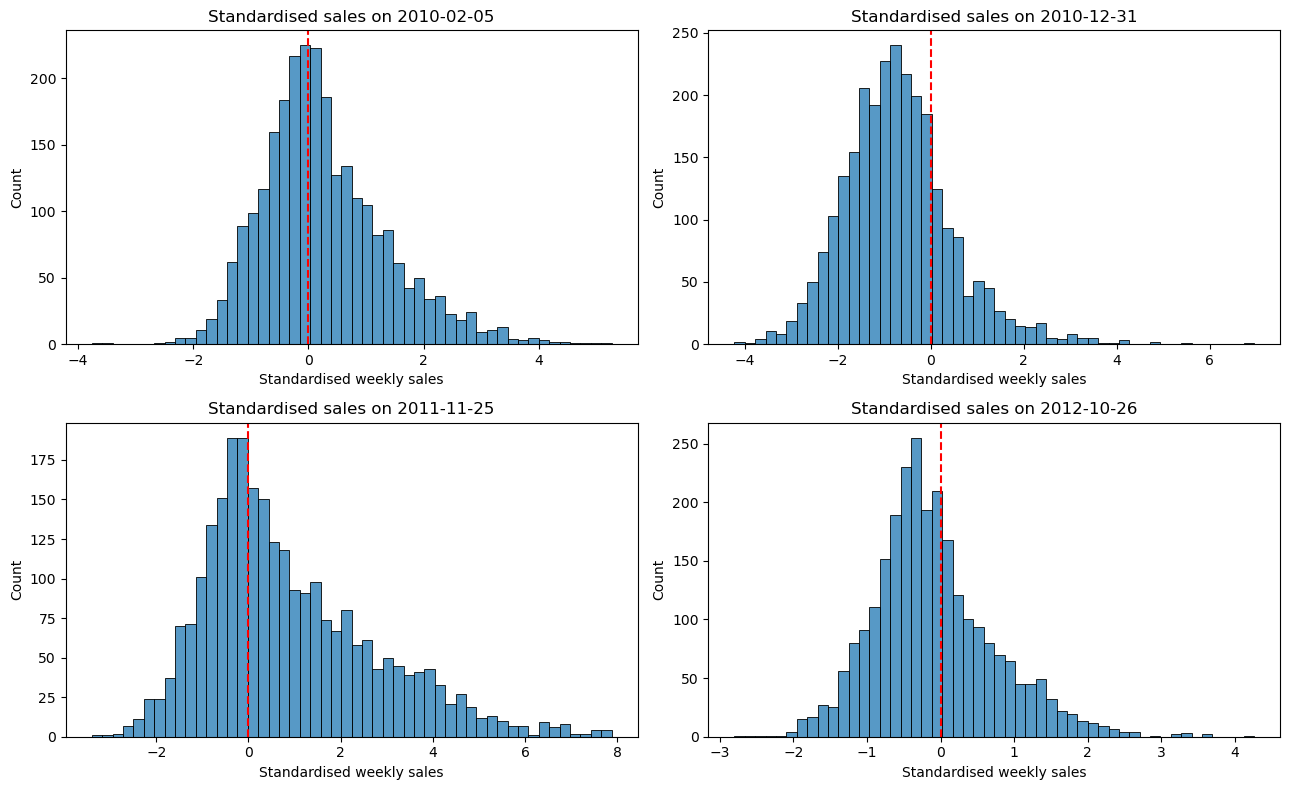

In [27]:
# Standardise each Store–Department sales trajectory across time
sales_matrix_standardised = sales_matrix.sub(
    sales_matrix.mean(axis=1), axis=0
).div(
    sales_matrix.std(axis=1), axis=0
)

# Plot standardised sales distributions for four weeks
chosen_dates = sales_matrix_standardised.columns[
    np.linspace(0, len(sales_matrix_standardised.columns) - 1, 4, dtype=int)
]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, date in zip(axes.flat, chosen_dates):
    sns.histplot(sales_matrix_standardised[date], bins=50, ax=ax)
    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(f"Standardised sales on {date.date()}")
    ax.set_xlabel("Standardised weekly sales")

plt.tight_layout()
plt.show()

# preprocessing - transform variables

Prepare the variables for your BUSPaS code

Using the BUSPaS algorithm, we want to identify Store–Department combinations with unusual sales shapes over time. To do this, each changing variable must be transformed into a fixed value per Store–Department if we want to include information about the other variables in the subgroup description.

An idea is to use the average values over all weeks for temperature, fuel price, CPI, and unemployment. These averages can be included as descriptive variables together with department, store type, and store size. BUSPaS can then identify subgroups such as stores with high average temperature or low average unemployment that have an unusual sales pattern over time. Moreover, to keep some more information we also add a column about the slope of change of these variables over the weeks.



The context variables are recorded once per Store–Date, but are repeated for every department in the merged data. We therefore first remove these duplicates, then calculate one mean and one linear time slope per store. A positive slope means that the variable generally increased over the 143 weeks; a negative slope means that it generally decreased.
is_holiday remains a week-level binary variable (0 = non-holiday week, 1 = holiday week). It should not be used as a fixed subgroup descriptor because every complete Store–Department trajectory contains holiday weeks, so a per-trajectory has_holiday column would be constant.

In [28]:
# Keep the holiday indicator as a binary WEEK-LEVEL variable.
# IsHoliday is already Boolean; this creates the requested 0/1 version.
walmart_data = walmart_data.copy()
walmart_data["is_holiday"] = walmart_data["IsHoliday"].astype("int8")

# These variables vary over time and will become fixed Store-level descriptors.
time_variables = ["Temperature", "Fuel_Price", "CPI", "Unemployment"]

# Do not calculate from all Store–Department rows: the values are repeated
# within each Store–Date after merging with the sales data.
store_weekly_context = (
    walmart_data[["Store", "Date", "is_holiday"] + time_variables]
    .drop_duplicates(subset=["Store", "Date"])
    .sort_values(["Store", "Date"])
)

print(store_weekly_context[["Store", "Date", "is_holiday"]].head())
print("Holiday coding:", dict(walmart_data[["IsHoliday", "is_holiday"]].drop_duplicates().values))

   Store       Date  is_holiday
0      1 2010-02-05           0
1      1 2010-02-12           1
2      1 2010-02-19           0
3      1 2010-02-26           0
4      1 2010-03-05           0
Holiday coding: {False: 0, True: 1}


In [29]:
# Calculate a mean and a linear slope for each time-varying variable.
# The slope is per weekly observation, using the observations in date order.
def time_slope(values):
    values = values.to_numpy(dtype=float)
    return np.polyfit(np.arange(len(values)), values, deg=1)[0]

store_descriptors = (
    store_weekly_context
    .groupby("Store", as_index=False)
    .agg(
        **{f"{variable}_mean": (variable, "mean") for variable in time_variables},
        **{f"{variable}_slope": (variable, time_slope) for variable in time_variables}
    )
)

display(store_descriptors.head())
print("One descriptor row per store:", store_descriptors.shape)

,Store,Temperature_mean,Fuel_Price_mean,CPI_mean,Unemployment_mean,Temperature_slope,Fuel_Price_slope,CPI_slope,Unemployment_slope
0,1,68.306783,3.219699,215.996892,7.610420,0.053001,0.008064,0.102295,-0.007330
1,2,68.216364,3.219699,215.646311,7.623846,0.057934,0.008064,0.102098,-0.013937
2,3,71.434196,3.219699,219.391531,7.176986,0.057213,0.008064,0.104196,-0.008221
3,4,62.253357,3.216972,128.679669,5.964692,0.085421,0.007840,0.043235,-0.033991
4,5,69.410140,3.219699,216.565581,6.295406,0.064048,0.008064,0.102613,-0.007812


One descriptor row per store: (45, 9)


In [30]:
# Add the fixed store characteristics.
# Type is already categorical; Size will be discretised below.
store_attributes = stores[["Store", "Type", "Size"]].drop_duplicates("Store")

store_descriptors = store_descriptors.merge(
    store_attributes,
    on="Store",
    how="left",
    validate="one_to_one"
)

assert store_descriptors[["Type", "Size"]].notna().all().all()

display(store_descriptors.head())

,Store,Temperature_mean,Fuel_Price_mean,CPI_mean,Unemployment_mean,Temperature_slope,Fuel_Price_slope,CPI_slope,Unemployment_slope,Type,Size
0,1,68.306783,3.219699,215.996892,7.610420,0.053001,0.008064,0.102295,-0.007330,A,151315
1,2,68.216364,3.219699,215.646311,7.623846,0.057934,0.008064,0.102098,-0.013937,A,202307
2,3,71.434196,3.219699,219.391531,7.176986,0.057213,0.008064,0.104196,-0.008221,B,37392
3,4,62.253357,3.216972,128.679669,5.964692,0.085421,0.007840,0.043235,-0.033991,A,205863
4,5,69.410140,3.219699,216.565581,6.295406,0.064048,0.008064,0.102613,-0.007812,B,34875


We also categorize the variables, because the buspas paper specifically said they discretize because the bus algorithm doesn't apply local discretization unlike bs.

We use equal-frequency tertiles: roughly the lowest third of stores are low, the middle third are medium, and the highest third are high. This produces categorical conditions that the subgroup search can use, such as Fuel_Price_mean = high. The categories are created at store level before being copied to every department in that store.

In [31]:
# Type is already categorical.
# Discretise the numerical descriptors, including store Size,
# into low, medium, and high equal-frequency groups.

continuous_descriptor_columns = [
    column for column in store_descriptors.columns
    if column not in ["Store", "Type"]
]

for column in continuous_descriptor_columns:
    store_descriptors[f"{column}_category"] = pd.qcut(
        store_descriptors[column],
        q=3,
        labels=["low", "medium", "high"]
    )

# Type can be used directly; all other rule variables use their categories.
category_columns = (
    ["Type"] +
    [f"{column}_category" for column in continuous_descriptor_columns]
)

display(store_descriptors[["Store"] + category_columns].head())

for column in category_columns:
    print(f"\n{column}")
    display(store_descriptors[column].value_counts(dropna=False).sort_index())

,Store,Type,Temperature_mean_category,Fuel_Price_mean_category,CPI_mean_category,Unemployment_mean_category,Temperature_slope_category,Fuel_Price_slope_category,CPI_slope_category,Unemployment_slope_category,Size_category
0,1,A,medium,low,high,medium,low,low,high,high,medium
1,2,A,medium,low,high,medium,low,low,high,low,high
2,3,B,high,low,high,low,low,low,high,medium,low
3,4,A,medium,low,low,low,high,low,low,low,high
4,5,B,high,low,high,low,medium,low,high,medium,low



Type


Type
A    22
B    17
C     6
Name: count, dtype: int64


Temperature_mean_category


Temperature_mean_category
low       15
medium    16
high      14
Name: count, dtype: int64

...

CPI_slope_category
low       19
medium    12
high      14
Name: count, dtype: int64


Unemployment_slope_category


Unemployment_slope_category
low       16
medium    14
high      15
Name: count, dtype: int64


Size_category


Size_category
low       15
medium    15
high      15
Name: count, dtype: int64

In [32]:
# One fixed descriptive row per Store–Department trajectory.
# These rows align with sales_matrix because both use Store and Dept as the key.
subgroup_data = (
    sales_matrix.reset_index()[["Store", "Dept"]]
    .merge(store_descriptors, on="Store", how="left", validate="many_to_one")
)

assert subgroup_data[category_columns].notna().all().all()
print("Subgroup-description data shape:", subgroup_data.shape)
display(subgroup_data.head())

Subgroup-description data shape: (2628, 21)


,Store,Dept,Temperature_mean,Fuel_Price_mean,CPI_mean,Unemployment_mean,Temperature_slope,Fuel_Price_slope,CPI_slope,Unemployment_slope,...,Size,Temperature_mean_category,Fuel_Price_mean_category,CPI_mean_category,Unemployment_mean_category,Temperature_slope_category,Fuel_Price_slope_category,CPI_slope_category,Unemployment_slope_category,Size_category
0,1,1,68.306783,3.219699,215.996892,7.61042,0.053001,0.008064,0.102295,-0.00733,...,151315,medium,low,high,medium,low,low,high,high,medium
1,1,2,68.306783,3.219699,215.996892,7.61042,0.053001,0.008064,0.102295,-0.00733,...,151315,medium,low,high,medium,low,low,high,high,medium
2,1,3,68.306783,3.219699,215.996892,7.61042,0.053001,0.008064,0.102295,-0.00733,...,151315,medium,low,high,medium,low,low,high,high,medium
3,1,4,68.306783,3.219699,215.996892,7.61042,0.053001,0.008064,0.102295,-0.00733,...,151315,medium,low,high,medium,low,low,high,high,medium
4,1,5,68.306783,3.219699,215.996892,7.61042,0.053001,0.008064,0.102295,-0.00733,...,151315,medium,low,high,medium,low,low,high,high,medium


Next, based on previous analysis, we also want to standardize the weekly sales

In [33]:
# Standardise each Store–Department sales trajectory across its 143 weeks
sales_matrix_shape = sales_matrix.sub(
    sales_matrix.mean(axis=1), axis=0
).div(
    sales_matrix.std(axis=1), axis=0
)

Finally, we can merge the features dataset and the weekly sales datasets

In [34]:
# Descriptive variables to use in subgroup rules
description_columns = ["Dept"] + category_columns

# One final row per Store–Department:
# descriptors + 143 standardised weekly sales values
final_data = (
    subgroup_data[["Store", "Dept"] + category_columns]
    .merge(
        sales_matrix_shape.reset_index(),
        on=["Store", "Dept"],
        how="inner",
        validate="one_to_one"
    )
)

print(final_data.shape)
display(final_data.head())

(2628, 155)


,Store,Dept,Type,Temperature_mean_category,Fuel_Price_mean_category,CPI_mean_category,Unemployment_mean_category,Temperature_slope_category,Fuel_Price_slope_category,CPI_slope_category,...,2012-08-24 00:00:00,2012-08-31 00:00:00,2012-09-07 00:00:00,2012-09-14 00:00:00,2012-09-21 00:00:00,2012-09-28 00:00:00,2012-10-05 00:00:00,2012-10-12 00:00:00,2012-10-19 00:00:00,2012-10-26 00:00:00
0,1,1,A,medium,low,high,medium,low,low,high,...,-0.631896,-0.591930,-0.425290,-0.293992,-0.331003,-0.361821,-0.061785,0.025439,0.169666,0.494958
1,1,2,A,medium,low,high,medium,low,low,high,...,-0.328299,1.422224,0.361095,-0.467490,-0.744337,-0.092229,0.719333,-1.159488,-1.089139,-0.862392
2,1,3,A,medium,low,high,medium,low,low,high,...,3.509287,4.311736,0.599155,0.130640,0.029068,-0.007409,-0.169193,-0.305812,-0.528375,-0.436283
3,1,4,A,medium,low,high,medium,low,low,high,...,-0.098777,0.286217,0.882082,-0.655166,-0.838303,-0.790537,0.801098,-0.517957,-0.482808,-0.229145
4,1,5,A,medium,low,high,medium,low,low,high,...,-0.159900,-0.497973,-0.531477,-0.431447,0.135993,-0.149824,0.110400,-0.294601,-0.339277,0.140243


or we can have the feature and target as two different inputs

In [35]:
description_columns = ["Dept"] + category_columns
target_columns = list(sales_matrix_shape.columns)

id_columns = ["Store", "Dept"]

X = final_data[description_columns]  # descriptions
Y = final_data[target_columns]       # sales trajectories

# Summary of the final datasets

## Final data preparation for BUSPaS and Beam Search

Our data are organised into three related datasets. Each dataset has one row for one **Store–Department** combination, representing one weekly sales trajectory.

### 1. Descriptive dataset: `subgroup_data`

`subgroup_data` contains the fixed descriptive information for each Store–Department combination. It includes:

- identifiers: `Store` and `Dept`;
- store `Type`;
- the numerical store `Size`;
- the numerical mean and slope of Temperature, Fuel Price, CPI, and Unemployment for each store;
- categorical versions of store size and of the mean and slope variables.

`Type` is already categorical and can be used directly in subgroup rules. Store size, the context-variable means, and the context-variable slopes are converted into `low`, `medium`, and `high` categories using equal-frequency tertiles across stores.

The numerical mean, slope, and size columns are retained for reference and interpretation. The categorical versions are used by the algorithms to define subgroup rules. For example:

```text
Type = A AND Size_category = high
```

or:

```text
Dept = 5 AND Fuel_Price_mean_category = high
```

`Store` is retained only as an identifier to align the descriptive data with the target trajectories. It is not used as a subgroup descriptor.

### 2. Target-value dataset: `sales_matrix_shape`

`sales_matrix_shape` contains the target values: 143 weekly sales values for each Store–Department combination.

Each sales trajectory is standardised separately. This removes differences in average sales level and scale, so the quality measure compares the **shape of sales over time** rather than simply identifying combinations with high or low sales.

The 143 weekly-sales columns are the target trajectory used to evaluate whether a subgroup has an exceptional long-term sales pattern.

### 3. Full input dataset: `final_data`

`final_data` combines the categorical descriptive variables from `subgroup_data` with the 143 standardised weekly-sales values from `sales_matrix_shape`.

It contains:

- `Store` and `Dept` as identifiers;
- `Dept`, `Type`, `Size_category`, and the categorical mean and slope variables as descriptive variables;
- 143 standardised weekly-sales columns as the target trajectory.

Therefore, `final_data` can be used as the single input dataset for BUSPaS and Beam Search. The algorithms use the descriptive categorical columns to generate subgroup rules and the weekly-sales columns to evaluate the exceptionality of each subgroup.

The binary variable `is_holiday` is retained as week-level information. It is not included as a fixed subgroup descriptor because every complete Store–Department trajectory contains the same holiday weeks. It therefore cannot distinguish one subgroup from another.

## Download dataset

In [36]:
# Save the final BUSPaS / Beam Search input dataset as a CSV file
final_data.to_csv(DATA_PATH + "final_walmart_data.csv", index=False)